# Week 2.1 | Which EGFR inhibitors would you compare?

A structural biologist has time to examine three drug–protein complexes. You have six medicines that inhibit the human epidermal growth factor receptor (EGFR). You met two of them, gefitinib and osimertinib, in the Week 1 ChEMBL practical. **Which three would you choose to represent a range of molecular structures?**

Start by looking at the drawings. A ring or a group of atoms might suggest that two drugs are similar. Molecular descriptors let you compare a specific property, and fingerprints give you a way to compare structural features with a numerical score. At the end, you will decide whether the results support your first choice and look at what a 3D complex can add.

## Learning objectives

By the end of the practical, you should be able to:

- Load the compound table from GitHub, select a molecule by its ID and identify a shared feature in two drawings.
- Compare a molecular graph, SMILES, SELFIES and InChI, and recognise when two SMILES describe the same molecule.
- Use calculated descriptors to compare the properties of two drugs.
- Explain how MACCS and Morgan fingerprints encode structure and interpret Tanimoto scores from RDKit.
- Review a short piece of Python, make a one-line correction and check it against the output.
- Justify a shortlist of three drugs with evidence from a drawing and a similarity score, and identify which coordinates you need to measure a drug–protein distance.

## Contents

The practical takes **3 hours**, including a 15-minute break.

- **Setup · 10 min** — Open Colab, load the data and read the research question.
- **1. Inspect six drugs · 20 min** — Compare the drawings and make your first shortlist.
- **2. Represent a molecule · 35 min** — Read a graph and three text formats. Review code that compares two SMILES.
- **3. Compare properties · 25 min** — Use descriptors to revisit a pair you chose from the drawings.
- **Break · 15 min**
- **4. Compare fingerprints · 45 min** — Compare MACCS and Morgan rankings, then review how the code selects the closest match.
- **5. Make your shortlist · 30 min** — Discuss your choice with another group and look at a bound structure.

Optional exercises at the end cover stereochemistry, a drug–protein distance, a larger similarity search and the radar plot.

In [ ]:
# Course data load directly from GitHub in the setup below.

### Set up Colab




**Optional GenAI prompt**

> Explain what RDKit and SELFIES are used for in this practical.

In [ ]:
# @title Install RDKit and SELFIES { display-mode: "form" }
%pip -q install rdkit selfies



**Optional GenAI prompt**

> Explain what pandas and the RDKit modules do in this notebook. Use two sentences.

In [ ]:
# @title Import the packages { display-mode: "form" }
from itertools import combinations

import pandas as pd
import selfies as sf
from IPython.display import display
from rdkit import Chem, DataStructs
from rdkit.Chem import Crippen, Descriptors, Draw, Lipinski, MACCSkeys, rdFingerprintGenerator, rdMolDescriptors

`read_csv` loads the course table from GitHub. `index_col="compound_id"` makes IDs such as `D05` the row labels. `head(6)` shows the six reference drugs.

**Optional GenAI prompt**

> Explain why we use the compound ID as a row label.

In [ ]:
data_url = "https://raw.githubusercontent.com/tcobanoglu/dadd-course-data/main/data/week2/egfr_compounds.csv"
collection = pd.read_csv(data_url, index_col="compound_id")
collection = collection.rename(columns={"name": "Drug"})
collection[["Drug", "smiles", "pdb_id"]].head(6)

,Drug,smiles,pdb_id
compound_id,,,
D01,Afatinib,CN(C)C/C=C/C(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2...,4G5J
D02,Osimertinib,C=CC(=O)Nc1cc(Nc2nccc(-c3cn(C)c4ccccc34)n2)c(O...,6JXT
D03,Erlotinib,C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1,1M17
D04,Lapatinib,CS(=O)(=O)CCNCc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5ccc...,1XKK
D05,Gefitinib,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1,2ITY
D06,Dacomitinib,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)/C=C/C...,4I23


**What the code does.** The first line keeps the six reference drugs. The second applies `Chem.MolFromSmiles` to each SMILES string to make an RDKit molecule.

**Optional GenAI prompt**

> Explain how this code goes from the SMILES column to six RDKit molecules.

In [ ]:
drugs = collection.loc[collection["reference"]].copy()
molecules = drugs["smiles"].map(Chem.MolFromSmiles)
print(f"{len(molecules)} drugs are ready.")

6 drugs are ready.


## 1. Inspect six drugs

In a 2D drawing, an unlabelled corner or line end usually represents a carbon atom. Lines show bonds, and letters such as N, O and F label other elements. Look for rings, branches and labelled atoms as you compare the drawings.

Run the cell for gefitinib. Then replace `"D05"` with `"D06"` and run it again to display dacomitinib.

`.loc` uses the ID to select the SMILES and the corresponding RDKit molecule. The last line draws that molecule.

**Optional GenAI prompt**

> Explain how the drug ID selects one molecule and its SMILES.

Gefitinib COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1


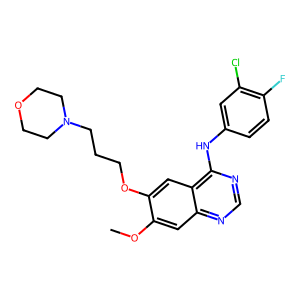

In [ ]:
drug_id = "D05"
smiles = drugs.loc[drug_id, "smiles"]
molecule = molecules.loc[drug_id]
print(drugs.loc[drug_id, "Drug"], smiles)
Draw.MolToImage(molecule)

The code makes the labels first, then draws all six molecules in a grid.

**Optional GenAI prompt**

> Explain how this code gets the names for the six drawings.

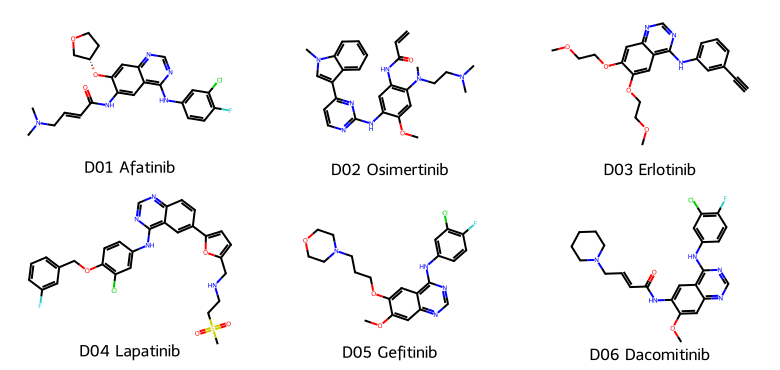

In [ ]:
# @title Draw the six inhibitors { display-mode: "form" }
drug_names = (drugs.index + " " + drugs["Drug"]).tolist()
structures = molecules.tolist()
Draw.MolsToGridImage(structures, legends=drug_names, molsPerRow=3, subImgSize=(260, 185))

**Discuss.**

Discuss with your partner. Identify one pair that seems similar and point to a feature you can trace in both drawings. Then choose three drugs whose drawings differ in a way you can describe

**Your notes**

…

## 2. Represent a molecule

The six drawings in Section 1 came from molecular structures stored as text. Ethanol is small enough to see how the same structure can be written in several ways.

| Representation | What it shows |
|---|---|
| **Molecular graph** | Atoms are points and bonds connect them. You can trace which atoms are neighbours. |
| **SMILES** | A short text description of a structure. `CCO` traces two carbons followed by oxygen. |
| **SELFIES** | A text format that uses bracketed pieces called tokens. For ethanol, these are `[C][C][O]`. |
| **InChI** | The International Chemical Identifier. It gives a standard text identifier for matching chemical records. Look for the molecular formula `C2H6O` in the output. |

**Try it.** Run the cell to see the labelled graph and the usual 2D drawing. The labelled graph shows the non-hydrogen atoms. Trace the two carbons and the oxygen in both drawings, then find them in the SMILES and SELFIES strings.

**What the code does.** RDKit reads `CCO` and draws ethanol. The code prints the three text formats and shows both drawings.

**Optional GenAI prompt**

> Explain how this cell uses `CCO` to draw ethanol and produce the text formats.

SMILES: CCO
SELFIES: [C][C][O]
InChI: InChI=1S/C2H6O/c1-2-3/h3H,2H2,1H3


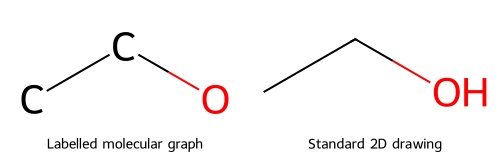

In [ ]:
# @title Show the four representations of ethanol { display-mode: "form" }
smiles = "CCO"
ethanol = Chem.MolFromSmiles(smiles)
selfies_text = sf.encoder(smiles)
inchi = Chem.MolToInchi(ethanol)

print("SMILES:", smiles)
print("SELFIES:", selfies_text)
print("InChI:", inchi)

graph = Chem.Mol(ethanol)
for atom in graph.GetAtoms():
    atom.SetProp("atomLabel", atom.GetSymbol())

labels = ["Labelled molecular graph", "Standard 2D drawing"]
Draw.MolsToGridImage([graph, ethanol], legends=labels, molsPerRow=2, subImgSize=(250, 160))

### Code review 1 · Do these SMILES describe the same molecule?

A SMILES string can also record stereochemistry. RDKit reads a SMILES string as a structure and can write it back as a **canonical SMILES**, a consistent text representation under the same settings.

| SMILES | What it describes |
|---|---|
| `CCO` and `OCC` | Ethanol written from opposite ends |
| `COC` | Dimethyl ether, with oxygen between the two carbons |

A colleague on your chemoinformatics team claims that the script below checks whether two database records describe the same molecule. Python’s `==` compares the two values on either side and returns `True` or `False`.

**Predict.** Write down what you expect the first line to print for `CCO` and `OCC`. Run the cell as written, then compare the result with the two drawings.

**Your notes**

…

**What the code does.** The cell reads two SMILES, displays a drawing of each structure and prints two comparisons.

**Optional GenAI prompt**

> Explain what the marked line compares. Suggest one edit using the canonical SMILES already in the code.

In [ ]:
first_smiles = "CCO"
second_smiles = "OCC"

first_molecule = Chem.MolFromSmiles(first_smiles)
second_molecule = Chem.MolFromSmiles(second_smiles)

first_key = Chem.MolToSmiles(first_molecule)
second_key = Chem.MolToSmiles(second_molecule)

same_molecule = first_smiles == second_smiles  # Review this line.
print("Same molecule?", same_molecule)

first_inchi = Chem.MolToInchi(first_molecule)
second_inchi = Chem.MolToInchi(second_molecule)
print("Same InChI?", first_inchi == second_inchi)

structures = [first_molecule, second_molecule]
labels = [first_smiles, second_smiles]
Draw.MolsToGridImage(structures, legends=labels, molsPerRow=2, subImgSize=(180, 135))

**Review and test.** After the first run, use the prompt above or trace the variables with a partner. The canonical SMILES are already stored as `first_key` and `second_key`. Change only the line marked **Review this line** and run it again. Then change `"OCC"` to `"COC"` and run it once more.

**Discuss.**

1. Record the comparison you changed and the result for each pair. Explain how the drawings and the InChI comparison helped you check your edit.
2. Two assays report activity for the same canonical structure. Would you average the two activity values? Which detail about the assays would you check first?

**Your notes**

…

## 3. Compare properties

A **molecular descriptor** is a number that summarises one property. Compare the pair from Section 1 using the values in the table. Afatinib (`D01`) and osimertinib (`D02`) are the worked example.

| Descriptor | What it describes |
|---|---|
| MW (g/mol) | Molecular weight |
| logP | Estimated preference for octanol over water. Higher values indicate a greater preference for octanol. |
| TPSA (Å²) | Estimated polar surface area based on the molecular structure |
| HBD | Number of hydrogen-bond donor sites |
| HBA | Number of hydrogen-bond acceptor sites |

 Each RDKit function calculates one descriptor for every molecule. The code stores the results in a table with one row per drug.

**Optional GenAI prompt**

> Explain how this cell turns the molecule list into a table with five descriptor columns.

In [ ]:
# @title Calculate the five descriptors { display-mode: "form" }
collection_molecules = collection["smiles"].map(Chem.MolFromSmiles)
collection_properties = pd.DataFrame(index=collection.index)

collection_properties["MW (g/mol)"] = collection_molecules.map(Descriptors.MolWt)
collection_properties["logP"] = collection_molecules.map(Crippen.MolLogP)
collection_properties["TPSA (Å²)"] = collection_molecules.map(rdMolDescriptors.CalcTPSA)
collection_properties["HBD"] = collection_molecules.map(Lipinski.NumHDonors)
collection_properties["HBA"] = collection_molecules.map(Lipinski.NumHAcceptors)

properties = collection_properties.loc[drugs.index]

  Run the cell, then replace the IDs in quotes with the two drugs you found similar. Change one ID at a time. Read the **same column** for both drugs.

**What the code does.** Add the drug names to the descriptor table. Use `.loc[pair]` to select the two rows, then round the values for display.

**Optional GenAI prompt**

> Explain how changing a drug ID changes the rows shown in the table.

In [ ]:
first_drug = "D01"
second_drug = "D02"

pair = [first_drug, second_drug]
property_table = drugs[["Drug"]].join(properties)
selected_properties = property_table.loc[pair]
selected_properties.round(2)

,Drug,MW (g/mol),logP,TPSA (Å²),HBD,HBA
compound_id,,,,,,
D01,Afatinib,485.95,4.39,88.61,2,7
D02,Osimertinib,499.62,4.51,87.55,2,7


**Discuss.**

1. Which descriptor supports your choice of a similar pair? Give the value for each drug.
2. What structural difference can you see in the drawings that the five descriptors leave out?

**Your notes**

…

### Break · 15 min

## 4. Compare fingerprints

A molecular **fingerprint** records features of a structure. In the binary fingerprints used here, a bit is on (1) when the fingerprint records a feature.

| Term | How it works |
|---|---|
| Substructure-based fingerprint | Records patterns within a molecule. A common approach is to check every molecule against the same list of predefined patterns. These are called structural keys. |
| MACCS fingerprint | A structural-key fingerprint. The public set defines 166 keys. Each key checks a predefined feature, such as a pattern of bonded atoms. |
| Circular fingerprint | Builds features around each atom by following bonds outward. The radius tells you how many bonds away to look. |
| Morgan fingerprint | A circular fingerprint. Here we look up to two bonds from each atom (radius 2) and store the resulting features in 2,048 bits. The settings used here ignore stereochemistry. |

For example, start at the oxygen in ethanol. One bond takes you to the adjacent carbon. Two bonds take you to the other carbon.

**Tanimoto similarity** is a score from 0 to 1. A higher score means the two fingerprints share a larger fraction of the bits that are on in either fingerprint. RDKit calculates the scores in this practical.

### Check what happens when the SMILES changes

**Try it.** Run the two cells below. Then change `"OCC"` to `"COC"`. Does the MACCS bit for an oxygen bonded to hydrogen change? What happens to the two similarity scores?

RDKit calculates both fingerprints from the structure it reads from SMILES. A score of 1 means the on-bits match for that fingerprint. Different molecules can share the same fingerprint.

**What the code does.** The first line sets up the Morgan method. Each of the next two lines makes one type of fingerprint for every drug.

**Optional GenAI prompt**

> Explain what each of these three lines does.

In [ ]:
# @title Prepare MACCS and Morgan fingerprints { display-mode: "form" }
morgan = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
maccs_fingerprints = molecules.map(MACCSkeys.GenMACCSKeys)
fingerprints = molecules.map(morgan.GetFingerprint)

**What the code does.** The SMILES in the first line selects the structure to compare with ethanol. The code makes two fingerprints of each type. It prints MACCS bit 139 and the two similarity scores.

**Optional GenAI prompt**

> Explain what the output tells us about ethanol and the molecule entered here.

In [ ]:
comparison_smiles = "OCC"
ethanol = Chem.MolFromSmiles("CCO")
other = Chem.MolFromSmiles(comparison_smiles)

# Make two MACCS fingerprints and compare them.
ethanol_maccs = MACCSkeys.GenMACCSKeys(ethanol)
other_maccs = MACCSkeys.GenMACCSKeys(other)
maccs_score = DataStructs.TanimotoSimilarity(ethanol_maccs, other_maccs)

# Repeat using Morgan fingerprints.
ethanol_morgan = morgan.GetFingerprint(ethanol)
other_morgan = morgan.GetFingerprint(other)
morgan_score = DataStructs.TanimotoSimilarity(ethanol_morgan, other_morgan)

same_structure = Chem.MolToSmiles(ethanol) == Chem.MolToSmiles(other)
print("Same canonical SMILES?", same_structure)
print("MACCS key 139 for CCO and", comparison_smiles, ":", ethanol_maccs[139], other_maccs[139])
print("MACCS similarity:", round(maccs_score, 3))
print("Morgan similarity:", round(morgan_score, 3))

Same canonical SMILES? True
MACCS key 139 for CCO and OCC : 1 1
MACCS similarity: 1.0
Morgan similarity: 1.0


**Discuss.** Use the drawings and the two sets of results to explain why changing a SMILES can leave the fingerprint as it was or change it.

**Your notes**

…

### Find the closest drug with MACCS and Morgan

A **reference drug** is the one you compare with the others. Start with gefitinib (`D05`). Look back at the drawings and predict which drug will rank first. Run both cells below. Each table ranks the other five drugs. The reference drug and Tanimoto calculation are the same in both tables.

 The code removes the reference drug from the candidates, calculates similarity scores and sorts the matches from highest to lowest.

**Optional GenAI prompt**

-----

In [ ]:
# @title Prepare the ranking and the code-review plot { display-mode: "form" }
import matplotlib.pyplot as plt

def rank_neighbours(query_id, library, library_fingerprints):
    query_fp = library_fingerprints.loc[query_id]
    candidates = library_fingerprints.drop(query_id)
    scores = DataStructs.BulkTanimotoSimilarity(query_fp, candidates.tolist())
    ranking = library.loc[candidates.index, ["Drug"]].copy()
    ranking["Tanimoto similarity"] = scores
    return ranking.sort_values("Tanimoto similarity", ascending=False, kind="stable")

def show_ranking_pick(ranking, selected_id):
    scores = ranking["Tanimoto similarity"]
    colours = ["#19698a" if drug_id == selected_id else "#bac5cb" for drug_id in ranking.index]
    labels = ranking.index + " " + ranking["Drug"]

    fig, ax = plt.subplots(figsize=(6.6, 2.8), layout="constrained")
    bars = ax.barh(labels, scores, color=colours)
    ax.bar_label(bars, fmt="%.4f", padding=4)
    ax.invert_yaxis()
    ax.set_xlim(0, scores.max() * 1.23)
    ax.set_xlabel("Morgan Tanimoto similarity")
    ax.set_title("The blue bar shows the drug selected by the script")
    plt.show()

 The drug ID selects the reference molecule. The output shows a MACCS ranking, a Morgan ranking and drawings of the top matches.

**Optional GenAI prompt**

> Explain how the reference ID changes the rankings and drawings.

In [ ]:
reference_drug = "D05"

maccs_ranking = rank_neighbours(reference_drug, drugs, maccs_fingerprints)
morgan_ranking = rank_neighbours(reference_drug, drugs, fingerprints)
print("MACCS ranking")
display(maccs_ranking.round(4))
print("Morgan ranking")
display(morgan_ranking.round(4))

maccs_match = maccs_ranking.index[0]
morgan_match = morgan_ranking.index[0]
top_ids = [reference_drug, maccs_match, morgan_match]
top_structures = molecules.loc[top_ids].tolist()
labels = ["Query: " + drugs.at[reference_drug, "Drug"],
          "MACCS: " + drugs.at[maccs_match, "Drug"],
          "Morgan: " + drugs.at[morgan_match, "Drug"]]
Draw.MolsToGridImage(top_structures, legends=labels, molsPerRow=3, subImgSize=(250, 175))

**Try it.** Replace `"D05"` with `"D06"` to use dacomitinib as the reference. Run the ranking cell again.

**Discuss.**

1. Which drug ranks first with each fingerprint? Find a feature in the drawings that dacomitinib shares with one of those drugs.
2. Look at the two highest Morgan scores. How far apart are they? How would you describe that difference to someone choosing which complex to examine?

**Your notes**

…

### Code review 2 · Did the script pick the closest drug?

A colleague says the script below selects the drug with the highest Morgan similarity to dacomitinib (`D06`). The table is sorted from highest to lowest score. In Python, the number in brackets after a row index selects a row by its position.

**Predict.** Look at the Morgan ranking for `D06` from the previous exercise. Write down which drug the script *should* pick. Look at the marked line and predict which row the script *will* pick. Then run it and check the blue bar.

**Your notes**

…

**What the code does.** The script selects one row from the ranking, highlights its score and draws that drug beside the reference.

**Optional GenAI prompt**

> Explain which row `[-1]` selects. Suggest one edit that picks the highest-scoring row.

In [ ]:
review_reference = "D06"
review_ranking = rank_neighbours(review_reference, drugs, fingerprints)

chosen_drug = review_ranking.index[-1]  # Review this line.
print("The script selected", drugs.at[chosen_drug, "Drug"])
show_ranking_pick(review_ranking, chosen_drug)

review_ids = [review_reference, chosen_drug]
review_structures = molecules.loc[review_ids].tolist()
review_labels = drugs.loc[review_ids, "Drug"].tolist()
Draw.MolsToGridImage(review_structures, legends=review_labels, molsPerRow=2, subImgSize=(250, 175))

**Review and test.** After the first run, use the prompt or work with a partner. Change only the number in the marked line. Run the cell again and check that the blue bar corresponds to the highest score. Then change the reference to `"D05"` and see whether your edit works for a second drug.

**Discuss.** Record the line you changed and one observation from the plot that verifies your edit. Compare the two drawings and point out one feature they share.

**Your notes**

…

## 5. Make your shortlist

The ranking in Section 4 compared each drug with a single reference. Now compare **all three pairs** within your shortlist using the Morgan fingerprints. For three drugs A, B and C, those pairs are A–B, A–C and B–C.

**Try it.** Run both cells. Then replace the three quoted IDs in the second cell with your first shortlist. The table shows the most similar pair at the top. If you want more variety, try replacing one member of that pair and check whether the highest score goes down.

**What the code does.** The function forms each pair once, calculates its Morgan-based Tanimoto score and puts the highest score first.

**Optional GenAI prompt**

> Explain how this code forms and scores the three pairs.

In [ ]:
# @title Prepare the three-pair comparison { display-mode: "form" }
def show_shortlist(selected_drugs):
    if len(selected_drugs) != 3 or len(set(selected_drugs)) != 3:
        print("Choose three different IDs from D01 to D06.")
        return
    if not set(selected_drugs).issubset(drugs.index):
        print("Use IDs from D01 to D06.")
        return

    rows = []
    for left, right in combinations(selected_drugs, 2):
        first_fp = fingerprints.loc[left]
        second_fp = fingerprints.loc[right]
        score = DataStructs.TanimotoSimilarity(first_fp, second_fp)
        rows.append([drugs.at[left, "Drug"], drugs.at[right, "Drug"], score])

    columns = ["First drug", "Second drug", "Tanimoto similarity"]
    scores = pd.DataFrame(rows, columns=columns)
    scores = scores.sort_values("Tanimoto similarity", ascending=False)
    display(scores.round(3))

**What the code does.** The list gives the three drug IDs to compare. The call below it runs the pair comparison using that list.

**Optional GenAI prompt**

> Show which pairs the code compares for these three IDs.

In [ ]:
selected_drugs = ["D01", "D02", "D05"]
show_shortlist(selected_drugs)

,First drug,Second drug,Tanimoto similarity
1,D01 Afatinib,D05 Gefitinib,0.441
0,D01 Afatinib,D02 Osimertinib,0.220
2,D02 Osimertinib,D05 Gefitinib,0.171


**Discuss with another group.** Compare the most similar pair in each shortlist. Would their drawings or scores make you replace one of your choices? Explain what you would gain by making the change.

Record your final three IDs. Support your selection with one visible structural difference and one similarity score.

**Your notes**

…

### From a 2D drawing to a bound structure

Open the **3D View** of [PDB entry 2ITY](https://www.rcsb.org/structure/2ITY). Look for gefitinib, labelled `IRE`, inside the EGFR kinase domain. Its **bound pose** describes how the ligand is positioned and oriented in the protein.

**Discuss.**

1. Which representation would you use to find gefitinib’s rings? What information would you need to measure the distance from a gefitinib atom to an EGFR atom?
2. Both ligand files end in `.sdf`. What detail in the file or its source would tell you which coordinates came from the protein–ligand complex? Compare [gefitinib_2d.sdf](https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/123631/SDF?record_type=2d) and [gefitinib_bound.sdf](https://models.rcsb.org/v1/2ity/ligand?auth_asym_id=A&label_comp_id=IRE&encoding=sdf).
3. If two records have the same canonical SMILES, what would you check before saying that they show the same pose?

**For Week 2.2.** Bring your shortlist and one question about how the selected drugs bind to EGFR.

**Your notes**

…

## Optional extensions

### Can a fingerprint tell mirror images apart?

These two SMILES describe mirror-image forms of lactic acid. The atoms connect in the same order. The `@` and `@@` labels indicate opposite configurations at the same carbon in these two strings.

**Try it.** Run the cell. Do the canonical SMILES match? Do the fingerprints match with the settings we used? What changes when Morgan includes stereochemistry?

**What the code does.** The code compares the two lactic acid structures with MACCS, with Morgan and with Morgan set to include stereochemistry.

**Optional GenAI prompt**

> Explain what changes when Morgan includes stereochemistry.

In [ ]:
# @title Compare the two forms of lactic acid { display-mode: "form" }
first = Chem.MolFromSmiles("C[C@H](O)C(=O)O")
second = Chem.MolFromSmiles("C[C@@H](O)C(=O)O")
morgan_with_stereo = rdFingerprintGenerator.GetMorganGenerator(
    radius=2, fpSize=2048, includeChirality=True
)
print("Same canonical SMILES?", Chem.MolToSmiles(first) == Chem.MolToSmiles(second))
for label, make_fingerprint in [
    ("MACCS", MACCSkeys.GenMACCSKeys),
    ("Morgan", morgan.GetFingerprint),
    ("Morgan with stereochemistry", morgan_with_stereo.GetFingerprint),
]:
    score = DataStructs.TanimotoSimilarity(make_fingerprint(first), make_fingerprint(second))
    print(f"{label} similarity: {score:.3f}")

Same canonical SMILES? False
MACCS similarity: 1.000
Morgan similarity: 1.000
Morgan with stereochemistry similarity: 0.692


### Measure a distance in the 2ITY complex

In the X-ray structure of the EGFR kinase domain with gefitinib, the ligand and protein atoms have coordinates in the same 3D frame. The code below uses coordinates for three atoms from chain A of the deposited model. `N3` is an atom in gefitinib. `N` and `O` are the backbone nitrogen and oxygen in the protein residue Met793.

**Try it.** Run the cell. Then replace `"N"` with `"O"` and run it again. Which protein atom is closer to the drug atom? Why would a 2D drawing of gefitinib alone be insufficient for this measurement?

[PubChem 2D SDF](https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/123631/SDF?record_type=2d) · [Bound ligand SDF](https://models.rcsb.org/v1/2ity/ligand?auth_asym_id=A&label_comp_id=IRE&encoding=sdf) · [Full 2ITY PDB file](https://files.rcsb.org/download/2ITY.pdb)

**What the code does.** The first line selects a protein atom. The code calculates the distance between that atom and the ligand nitrogen using their 3D coordinates.

**Optional GenAI prompt**

> Explain how the two sets of coordinates give an atom-to-atom distance.

In [ ]:
protein_atom = "N"

from math import dist

# Coordinates in ångströms from 2ITY, chain A.
ligand_n3 = (-54.287, 1.766, -21.024)
met793 = {'N': (-56.510, 2.925, -20.106), 'O': (-55.739, 0.966, -17.619)}

distance = dist(ligand_n3, met793[protein_atom])
print(f"N3 to Met793 {protein_atom}: {distance:.2f} Å")

N3 to Met793 N: 2.67 Å


### Search the larger collection

Your first ranking used only the six reference drugs. The course collection contains 22 more compounds tested against EGFR in the TeachOpenCADD dataset. Compare this search’s top score with the top Morgan score for gefitinib in Section 4. Which ligand gives the higher score?

[TeachOpenCADD T001 · EGFR data and provenance](https://projects.volkamerlab.org/teachopencadd/talktorials/T001_query_chembl.html)

**What the code does.** The code reuses the full GitHub table, calculates Morgan fingerprints and displays the five closest matches to gefitinib.

**Optional GenAI prompt**

> Explain how this search goes from all 28 compounds to five ranked matches.

In [ ]:
# @title Search all 28 compounds { display-mode: "form" }
collection_fingerprints = collection_molecules.map(morgan.GetFingerprint)
collection_ranking = rank_neighbours("D05", collection, collection_fingerprints)
collection_ranking.head(5).round(3)

,Drug,Tanimoto similarity
compound_id,,
D07,CHEMBL14699,0.919
D08,CHEMBL299672,0.857
D09,CHEMBL291514,0.844
D10,CHEMBL57758,0.785
D11,CHEMBL2425092,0.783


### Read a radar plot

The table in Section 3 shows the original values. A radar plot puts these descriptors on separate spokes and scales each one from 0 to 1 using the smallest and largest values in the 28-compound collection. Run the descriptor calculation in Section 3 first. This plot uses the pair you chose in Section 3.

**Discuss.** Suppose a new compound has a higher TPSA than all 28 compounds. What would happen to your two drugs’ positions on the TPSA spoke after rescaling? What TPSA values would still appear in the table?

The code scales each descriptor using its range across all 28 compounds and plots the scaled values for your selected pair.

**Optional GenAI prompt**

> Explain what 0 and 1 mean on one spoke of the radar plot.


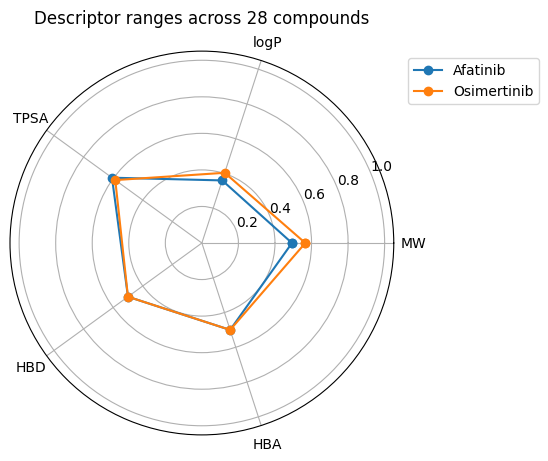

In [ ]:
# @title Plot the five scaled descriptors { display-mode: "form" }
import matplotlib.pyplot as plt
import numpy as np

minimum = collection_properties.min()
maximum = collection_properties.max()
scaled_pair = (properties.loc[pair] - minimum) / (maximum - minimum)

angles = np.linspace(0, 2 * np.pi, len(properties.columns), endpoint=False)
closed_angles = np.append(angles, angles[0])
figure, axis = plt.subplots(figsize=(5.5, 4.5), subplot_kw={"projection": "polar"}, layout="constrained")
for drug_id, values in scaled_pair.iterrows():
    axis.plot(closed_angles, np.append(values, values.iloc[0]), marker="o", label=drugs.at[drug_id, "Drug"])
axis.set_xticks(angles, ["MW", "logP", "TPSA", "HBD", "HBA"])
axis.set_ylim(0, 1.05)
axis.set_title("Descriptor ranges across 28 compounds", pad=20)
axis.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

Which descriptor in the table best supports your choice? Give its value for each drug.
What is one difference you can see in the drawings that the five descriptor values do not capture?
Suppose you add a compound with a higher TPSA than all the others. How would that change where your two drugs appear on the plot?

## References

- [AI-Guided Inquiry Learning (AGIL)](https://github.com/dayanjan/AGIL-VIP-AI-PSCI-Public) informed the code review exercises and the checks students use to verify their edits.
- TeachOpenCADD [T033 Molecular representations](https://projects.volkamerlab.org/teachopencadd/talktorials/T033_molecular_representations.html), [T002 Molecular filtering](https://projects.volkamerlab.org/teachopencadd/talktorials/T002_compound_adme.html), [T004 Compound similarity](https://projects.volkamerlab.org/teachopencadd/talktorials/T004_compound_similarity.html) and [T008 Protein Data Bank](https://projects.volkamerlab.org/teachopencadd/talktorials/T008_query_pdb.html) informed the order of topics.
- [RDKit Getting Started](https://www.rdkit.org/docs/GettingStartedInPython.html) covers drawing molecules, calculating descriptors and working with fingerprints.
- [SELFIES documentation](https://selfies.readthedocs.io/en/latest/) and the [IUPAC definition of InChI](https://goldbook.iupac.org/terms/view/11456) describe two text formats for chemical structures.
- The [course CSV](https://github.com/tcobanoglu/dadd-course-data/blob/main/data/week2/egfr_compounds.csv) contains the 28 selected structures. The SMILES and ChEMBL IDs come from the [TeachOpenCADD EGFR compound table](https://raw.githubusercontent.com/volkamerlab/teachopencadd/ea055ef7b14d57eda20482c42c7b39da0fd8368a/teachopencadd/talktorials/T001_query_chembl/data/EGFR_compounds.csv). The 22 comparison compounds were chosen from its Lipinski-filtered set to include close neighbours of gefitinib and osimertinib. The experimental example comes from [RCSB PDB entry 2ITY](https://www.rcsb.org/structure/2ITY).